# Đề tài 11 · Huấn luyện và kiểm chứng
So sánh 4 thuật toán × 3 cách xử lý dữ liệu AI4I mất cân bằng. Chọn mô hình theo AP validation. Chọn ngưỡng chính bằng chi phí bỏ sót và báo nhầm.

**Trên Colab**: chạy ô bên dưới và chọn đúng ZIP demo khi được yêu cầu. **Trên Jupyter**: mở notebook trong thư mục demo đã giải nén và cài hai tệp requirements theo README.

In [1]:
from pathlib import Path
from tempfile import mkdtemp
from zipfile import ZipFile
from io import BytesIO
import importlib.util
import os
import subprocess
import sys

project = Path.cwd()
in_colab = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") else False
if not (project / "train.py").is_file() and in_colab:
    from google.colab import files
    uploaded = files.upload()
    archives = [content for name, content in uploaded.items() if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Chọn đúng một ZIP demo Đề tài 11.")
    project = Path(mkdtemp(prefix="nhom16_demo_"))
    with ZipFile(BytesIO(archives[0])) as archive:
        for member in archive.infolist():
            if not (project / member.filename).resolve().is_relative_to(project.resolve()):
                raise ValueError("ZIP có tên tệp không hợp lệ.")
        archive.extractall(project)

if not (project / "train.py").is_file():
    raise FileNotFoundError("Mở notebook trong thư mục demo đã giải nén.")

if in_colab:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "-r", "requirements.txt", "-r", "requirements-train.txt"], cwd=project, check=True)

print("Đã tìm thấy mã huấn luyện và dữ liệu đi kèm.")

Đã tìm thấy mã huấn luyện và dữ liệu đi kèm.


## 1. Kiểm tra nguồn và nhãn
AI4I 2020 là dữ liệu mô phỏng. Nhãn `Machine failure` dùng để học và đối chiếu. Năm cột loại hỏng và hai cột định danh được loại khỏi đầu vào. [Nguồn UCI](https://archive.ics.uci.edu/dataset/601/ai4i).

In [2]:
import pandas as pd
from IPython.display import display, Image

raw = pd.read_csv(project / "data" / "ai4i2020.csv")
target = raw["Machine failure"]
display(pd.DataFrame({"Tổng số bản ghi": [len(raw)], "Bình thường": [target.eq(0).sum()],
                      "Hỏng": [target.eq(1).sum()], "Tỷ lệ hỏng": [target.mean()]}))
print("Ô thiếu:", int(raw.isna().sum().sum()))
print("Dòng trùng:", int(raw.duplicated().sum()))

Ô thiếu: 0
Dòng trùng: 0


,Tổng số bản ghi,Bình thường,Hỏng,Tỷ lệ hỏng
0,10000,9661,339,0.0339


## 2. Huấn luyện 12 cấu hình
Script chia phân tầng train/validation/test theo tỷ lệ 70/15/15. SMOTENC chỉ lấy mẫu trên train và xử lý `Type` như biến phân loại. Mọi cấu hình dùng cùng validation gốc. Kịch bản chính giả định bỏ sót tốn gấp 5 lần báo nhầm.

In [3]:
run = Path(mkdtemp(prefix="nhom16_de_tai_11_"))
env = dict(os.environ, OMP_NUM_THREADS="2", OPENBLAS_NUM_THREADS="2")
result = subprocess.run(
    [sys.executable, str(project / "train.py"), "--csv", str(project / "data" / "ai4i2020.csv"),
     "--output", str(run), "--miss-cost", "5"],
    cwd=project, env=env, capture_output=True, text=True,
)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    result.check_returncode()
reports = run / "reports"
display(pd.read_csv(reports / "split_counts.csv"))

Huấn luyện Logistic Regression / Original
Huấn luyện Random Forest / Original
Huấn luyện XGBoost / Original
Huấn luyện LightGBM / Original
Huấn luyện Logistic Regression / Weighted
Huấn luyện Random Forest / Weighted
Huấn luyện XGBoost / Weighted
Huấn luyện LightGBM / Weighted
Huấn luyện Logistic Regression / SMOTENC
Huấn luyện Random Forest / SMOTENC
Huấn luyện XGBoost / SMOTENC
Huấn luyện LightGBM / SMOTENC
     Split  Threshold  Accuracy  Precision   Recall       F1       AP  PR_AUC_trapezoid    Brier   TN  FP  FN  TP
     Train   0.198519  0.992714   0.852273 0.949367 0.898204 0.975683          0.975653 0.004930 6724  39  12 225
Validation   0.198519  0.978667   0.641791 0.843137 0.728814 0.783474          0.780019 0.013170 1425  24   8  43
      Test   0.198519  0.978667   0.655738 0.784314 0.714286 0.800627          0.799256 0.013093 1428  21  11  40
Đã lưu kết quả tại /tmp/nhom16_de_tai_11_yr4_62x0



,Split,Samples,Normal,Failure,Failure rate
0,Train,7000,6763,237,0.033857
1,Validation,1500,1449,51,0.034000
2,Test,1500,1449,51,0.034000


## 3. So sánh cách xử lý mất cân bằng
AP và PR-AUC đo trên dãy điểm. F1, số ca và chi phí trong bảng dưới dùng ngưỡng chi phí của từng cấu hình, chọn trên validation.

In [4]:
comparison = pd.read_csv(reports / "validation_comparison.csv")
display(comparison[["Model", "Fit normal", "Fit failure", "AP", "PR_AUC_trapezoid",
                    "Threshold", "F1", "TP", "FN", "FP", "Cost"]].round(4))

,Model,Fit normal,Fit failure,AP,PR_AUC_trapezoid,Threshold,F1,TP,FN,FP,Cost
0,LightGBM / Original,6763,237,0.7835,0.7800,0.1985,0.7288,43,8,24,64
1,Random Forest / Original,6763,237,0.7539,0.7508,0.2396,0.7368,42,9,21,66
2,XGBoost / Original,6763,237,0.7521,0.7491,0.2693,0.7477,40,11,16,71
3,LightGBM / Weighted,6763,237,0.7314,0.7288,0.6010,0.6833,41,10,28,78
4,LightGBM / SMOTENC,6763,6763,0.7252,0.7229,0.5324,0.5972,43,8,50,90
5,XGBoost / SMOTENC,6763,6763,0.6930,0.6893,0.5423,0.5931,43,8,51,91
6,Random Forest / Weighted,6763,237,0.6887,0.6834,0.2328,0.6462,42,9,37,82
7,Random Forest / SMOTENC,6763,6763,0.6626,0.6589,0.5515,0.6387,38,13,30,95
8,XGBoost / Weighted,6763,237,0.6502,0.6422,0.5947,0.6557,40,11,31,86
9,Logistic Regression / Original,6763,237,0.3881,0.3837,0.2676,0.4565,21,30,20,170


## 4. Chọn ngưỡng và kiểm chứng
So sánh chi phí `5 × FN + FP` với ngưỡng tối đa F1, ngưỡng 0,5 và phương án luôn đoán bình thường. Mô hình và ngưỡng được ghi trước khi tính điểm trên test. Tập test đã được dùng ở vòng phát triển trước.

,Split,Policy,Threshold,TP,FN,FP,F1,Cost
0,Validation,Cost,0.198519,43,8,24,0.728814,64
1,Validation,F1,0.266037,40,11,12,0.776699,67
2,Validation,0.5,0.500000,33,18,8,0.717391,98
3,Validation,All normal,0.500000,0,51,0,0.000000,255
4,Test,Cost,0.198519,40,11,21,0.714286,76
5,Test,F1,0.266037,38,13,16,0.723810,81
6,Test,0.5,0.500000,32,19,5,0.727273,100
7,Test,All normal,0.500000,0,51,0,0.000000,255


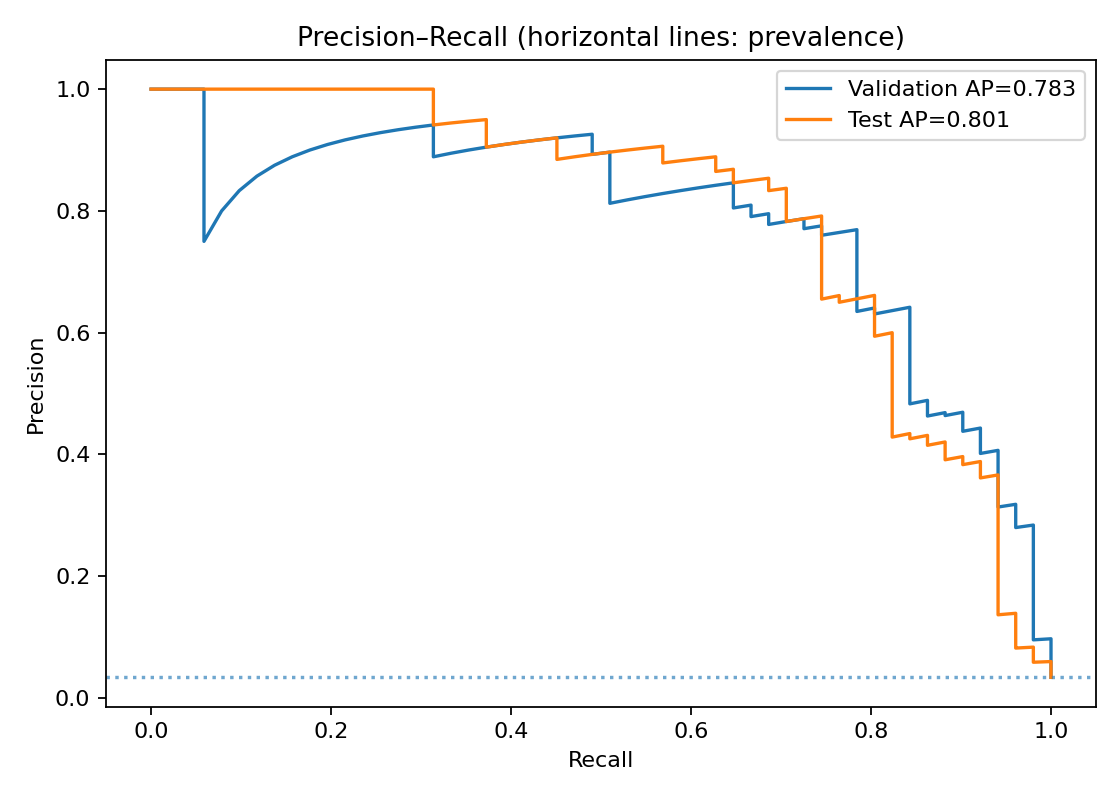

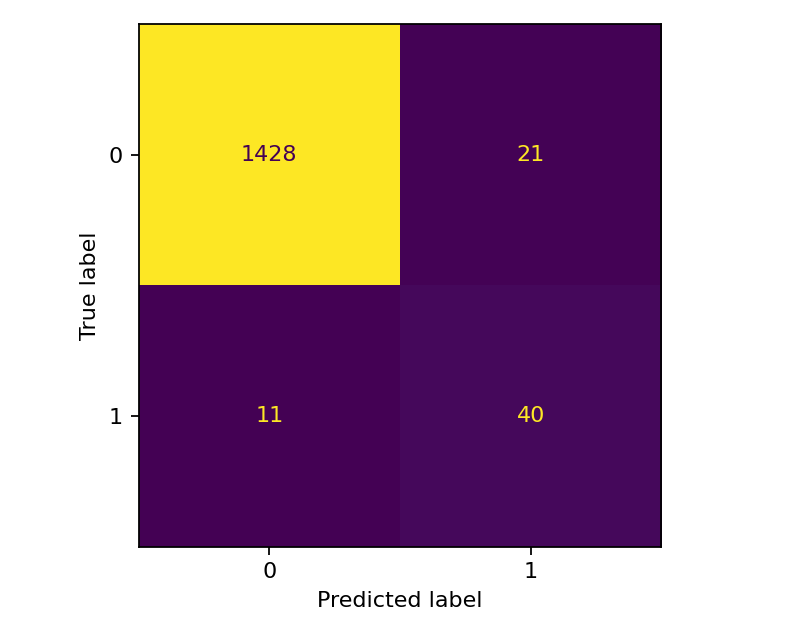

In [5]:
policies = pd.read_csv(reports / "policy_comparison.csv")
display(policies[["Split", "Policy", "Threshold", "TP", "FN", "FP", "F1", "Cost"]].round(6))
display(Image(filename=str(reports / "pr_curve.png")))
display(Image(filename=str(reports / "confusion_test.png")))

## 5. Kiểm tra khả năng tái lập
Đối chiếu điểm và nhãn của lần chạy lại với kết quả đóng gói cùng demo.

In [6]:
import numpy as np

name = "predictions_test.csv"
retrained = pd.read_csv(reports / name).sort_values("source_row")
packaged = pd.read_csv(project / "reports" / name).sort_values("source_row")
for column in ("source_row", "actual", "prediction"):
    np.testing.assert_array_equal(retrained[column], packaged[column])
np.testing.assert_allclose(retrained.probability, packaged.probability, atol=1e-8, rtol=0)
print("Khớp thứ tự mẫu, nhãn gốc, dự đoán và điểm test của gói demo.")

Khớp thứ tự mẫu, nhãn gốc, dự đoán và điểm test của gói demo.
